# Analyze Imaging Mass Cytometry (IMC)

### Data:
breast cancer tissue from Jackson et al. (2020). Each cell is alredy labelled with their cell types (tumour cells, T cells, marophages, stromal cells).

### Workflow:
1. Plot cell types in space
2. Co-occurrence
3. Neighbourhood enrichment
4. Interaction amtrix
5. Centrality scores

In [1]:
import squidpy as sq
print(f"squidpy=={sq.__version__}")
adata = sq.datasets.imc()

/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


squidpy==1.8.3
INFO     Downloading imc.h5ad from https://exampledata.scverse.org/squidpy/imc.h5ad                                


100%|█████████████████████████████████████| 1.57M/1.57M [00:00<00:00, 3.46GB/s]


/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


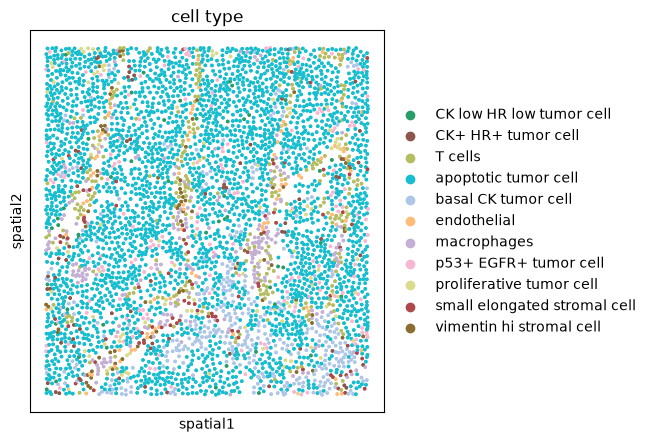

In [2]:
# visualise the cluster annotation
sq.pl.spatial_scatter(adata, shape=None, color="cell type", size=10)

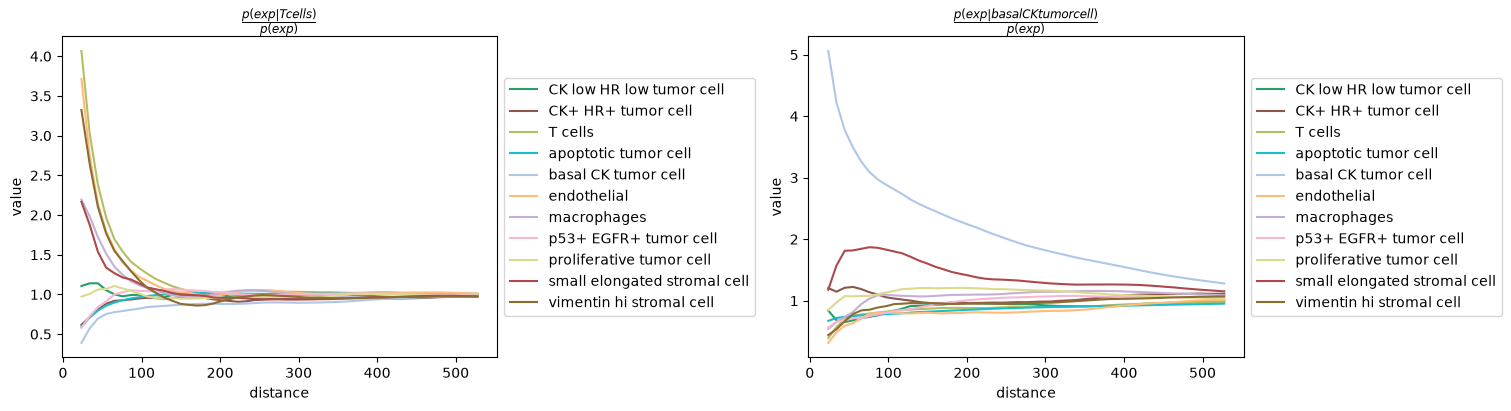

In [ ]:
# co-occurence
# the unit is each cell not spot
# score = (share of type X within a circle around type Y) / (share of type X overall)
sq.gr.co_occurrence(adata, cluster_key="cell type")
sq.pl.co_occurrence(
    adata,
    cluster_key="cell type",
    clusters=["basal CK tumor cell", "T cells"],
    figsize=(15, 4),
)

# around T cells, there are more endothelial cells and vimentin high stromal cells in short distances 
# therfore, T cells sits near vesessls and stromal cells, which is expected in the tumour microenvironment
# around basal CK tumour cells, other basal CK tumour cells are enriched in short distances
# which is expected as tumour cells are clonal and proliferate together

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_58973/3071539166.py:3: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata)
100%|██████████| 1000/1000 [00:03<00:00, 286.94/s]


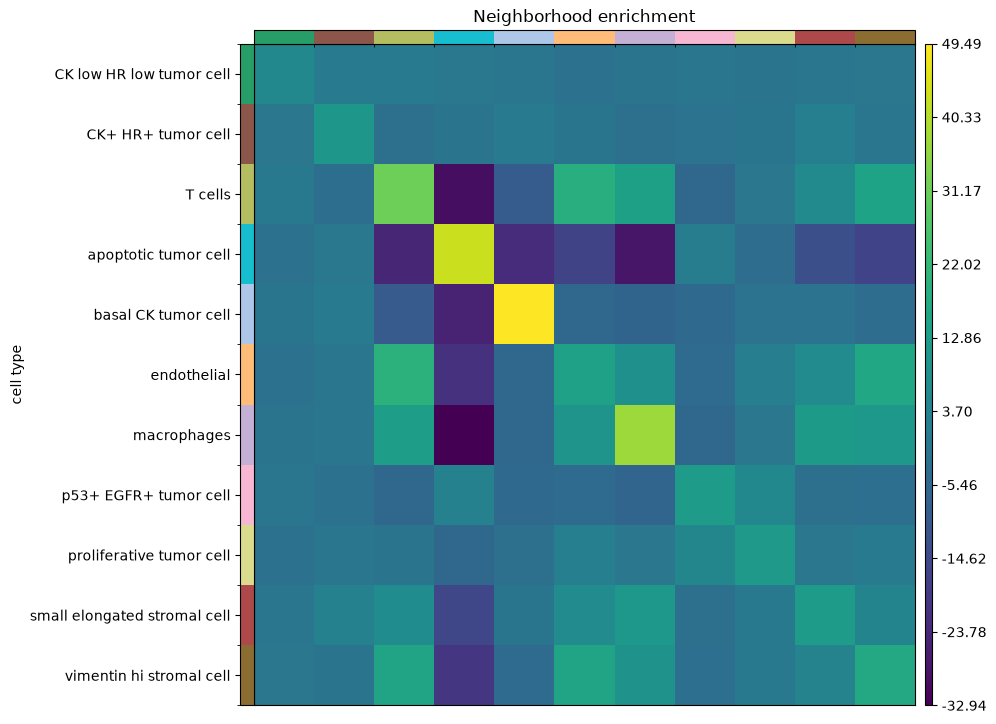

In [ ]:
# Neighbourhood enrichment to find out whether cell types are arranged in a non-random manner
# 6 nearest neighbours are used to define the neighbourhood of each cell
sq.gr.spatial_neighbors(adata)
sq.gr.nhood_enrichment(adata, cluster_key="cell type")
sq.pl.nhood_enrichment(adata, cluster_key="cell type")

# T cells are enriched in the neighbourhood of endothelial cells, macrophages and vimentin high stromal cells
# which is expected as T cells are recruited to the tumour microenvironment by macrophages and vessels
# apoptotic cells are enriched in the neighbourhood of other tumour cells but depleted with every other types
# this seems due to high number of apoptotic cells uniformly spread across the tissue due ot permutation

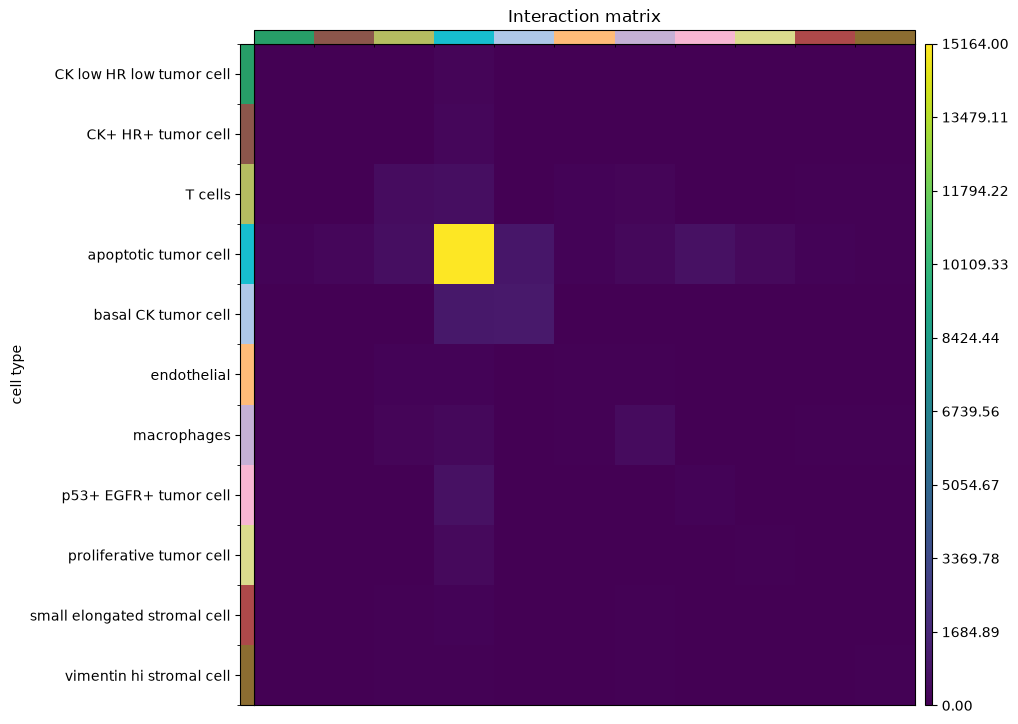

In [5]:
# Interaction matrix 
# raw counts of the number of edges that each cluster share with all the others
# this is different with neighbourhood enrichment as it does nto involve shuffling and p value
sq.gr.interaction_matrix(adata, cluster_key="cell type")
sq.pl.interaction_matrix(adata, cluster_key="cell type")

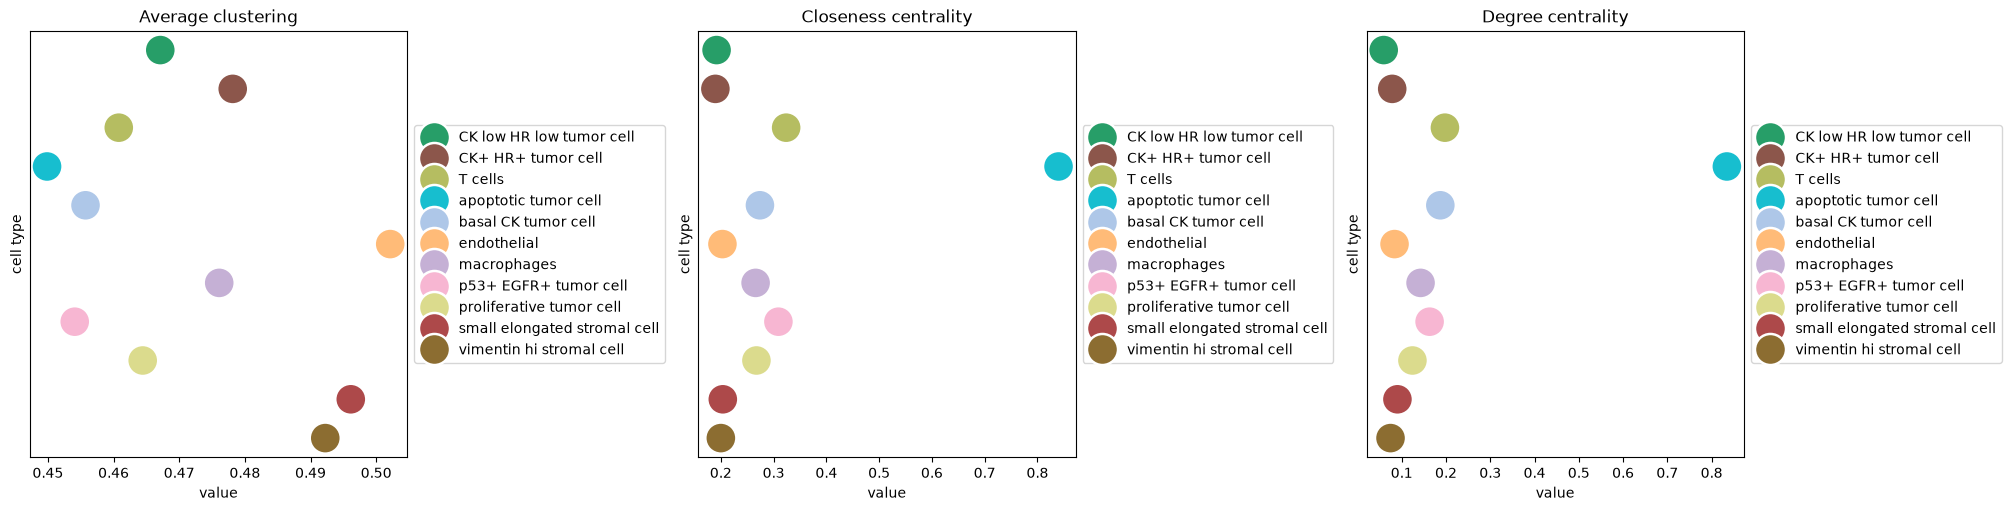

In [ ]:
# Centrality scores
# degree centrality: number of edges that a cluster has with other clusters
# average clustering coefficient: how likely a cluster's neighbours also neighbours of each other
# closeness centrality: how close a cluster is to all other clusters in the network
sq.gr.centrality_scores(
    adata,
    cluster_key="cell type",
)
sq.pl.centrality_scores(adata, cluster_key="cell type", figsize=(20, 5), s=500)

# apoptotic tumour cells have high closeness centrality, which means they are close to all other clusters in the network